# Data Load
## CSV Load

In [18]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

import pandas as pd
data = pd.read_csv("givemesomecredit.csv")
data.head()
data.shape

(150000, 9)

In [3]:
# 임시 축약어 매핑 딕셔너리
short_names = {
    'SeriousDlqin2yrs': 'Dlq2yrs',
    'RevolvingUtilizationOfUnsecuredLines': 'RevUtil',
    'age': 'Age',
    'NumberOfTime30-59DaysPastDueNotWorse': 'PastDue_30-59',
    'DebtRatio': 'DebtRatio',
    'MonthlyIncome': 'Income',
    'NumberOfDependents': 'Dependents',
    'CombinedDefaulted': 'CombDefault',
    'CombinedCreditLoans': 'CombCredit'
}

data = data.rename(columns=short_names)

## Descriptive Statistics

In [4]:
d = data.dtypes
n = data.isnull().sum()
s = data.skew()
dn = pd.DataFrame((s, n, d), index=['skew', 'isnull', 'dtypes']).T
desc = data.describe().T
result = pd.concat([desc, dn],axis=1)
result.round(3)

class_counts = data.groupby('Dlq2yrs').size()
class_counts

,count,mean,std,min,25%,50%,75%,max,skew,isnull,dtypes
Dlq2yrs,150000.0,0.067,0.250,0.0,0.000,0.000,0.000,1.0,3.468857,0,int64
RevUtil,150000.0,6.048,249.755,0.0,0.030,0.154,0.559,50708.0,97.631574,0,float64
Age,150000.0,52.296,14.771,21.0,41.000,52.000,63.000,109.0,0.189244,0,int64
PastDue_30-59,150000.0,0.421,4.193,0.0,0.000,0.000,0.000,98.0,22.597108,0,int64
DebtRatio,150000.0,353.005,2037.819,0.0,0.175,0.367,0.868,329664.0,95.157793,0,float64
Income,150000.0,6673.266,12880.469,0.0,3903.000,6600.000,7400.000,3008750.0,127.356561,0,int64
Dependents,150000.0,0.737,1.107,0.0,0.000,0.000,1.000,20.0,1.626059,0,int64
CombDefault,150000.0,0.202,0.402,0.0,0.000,0.000,0.000,1.0,1.481236,0,int64
CombCredit,150000.0,0.742,0.437,0.0,0.000,1.000,1.000,1.0,-1.109198,0,int64


Dlq2yrs
0    139974
1     10026
dtype: int64

# Visualisation
## Univariate
### Histogram

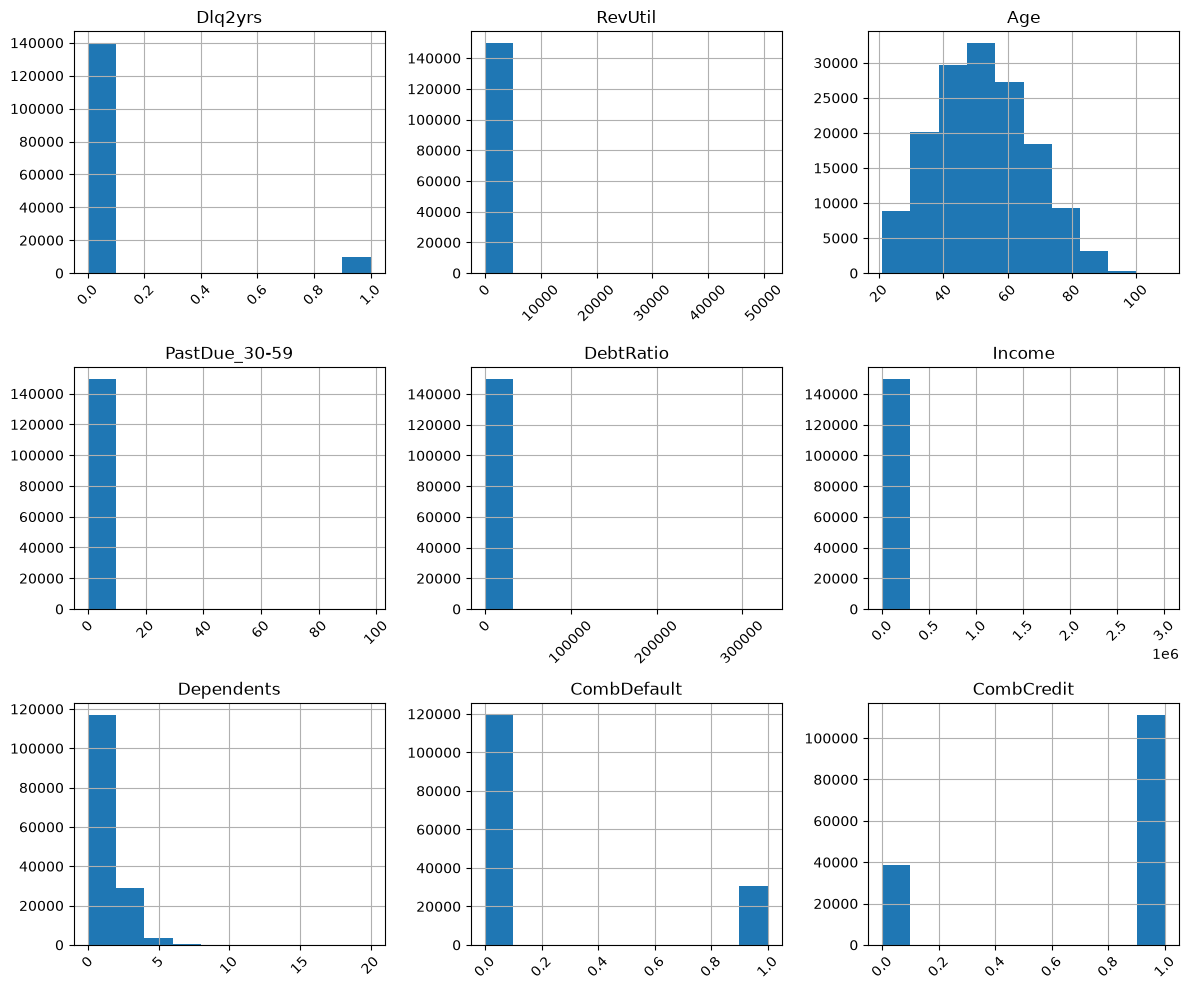

In [5]:
from matplotlib import pyplot as plt
data.hist(figsize=(12, 10), xrot=45)
plt.tight_layout()
plt.show();

### Density Plot

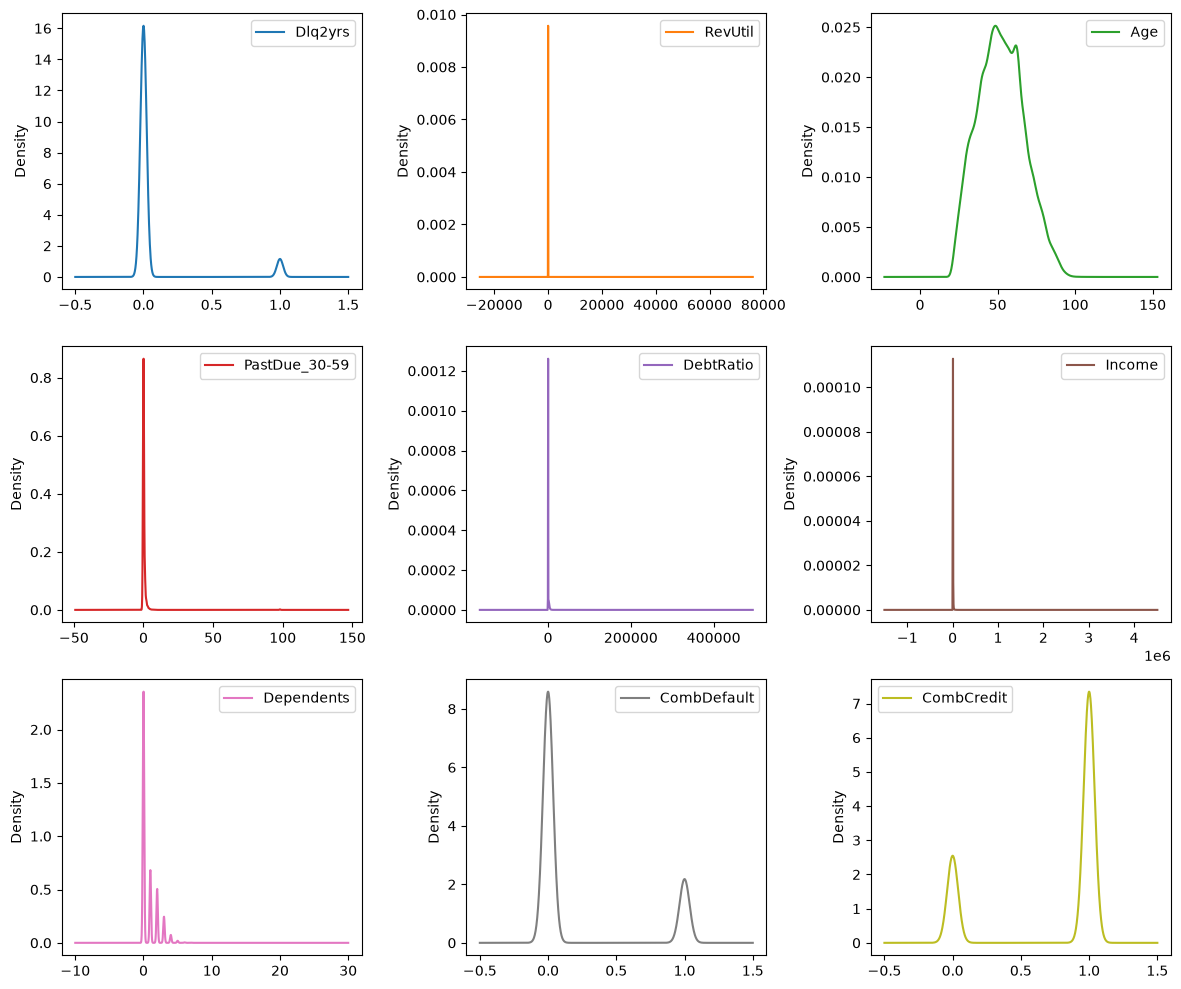

In [6]:
data.plot(figsize=(12,10), kind='density', subplots=True, layout=(3, 3), sharex=False)
plt.tight_layout()
plt.show();

### Box Plot

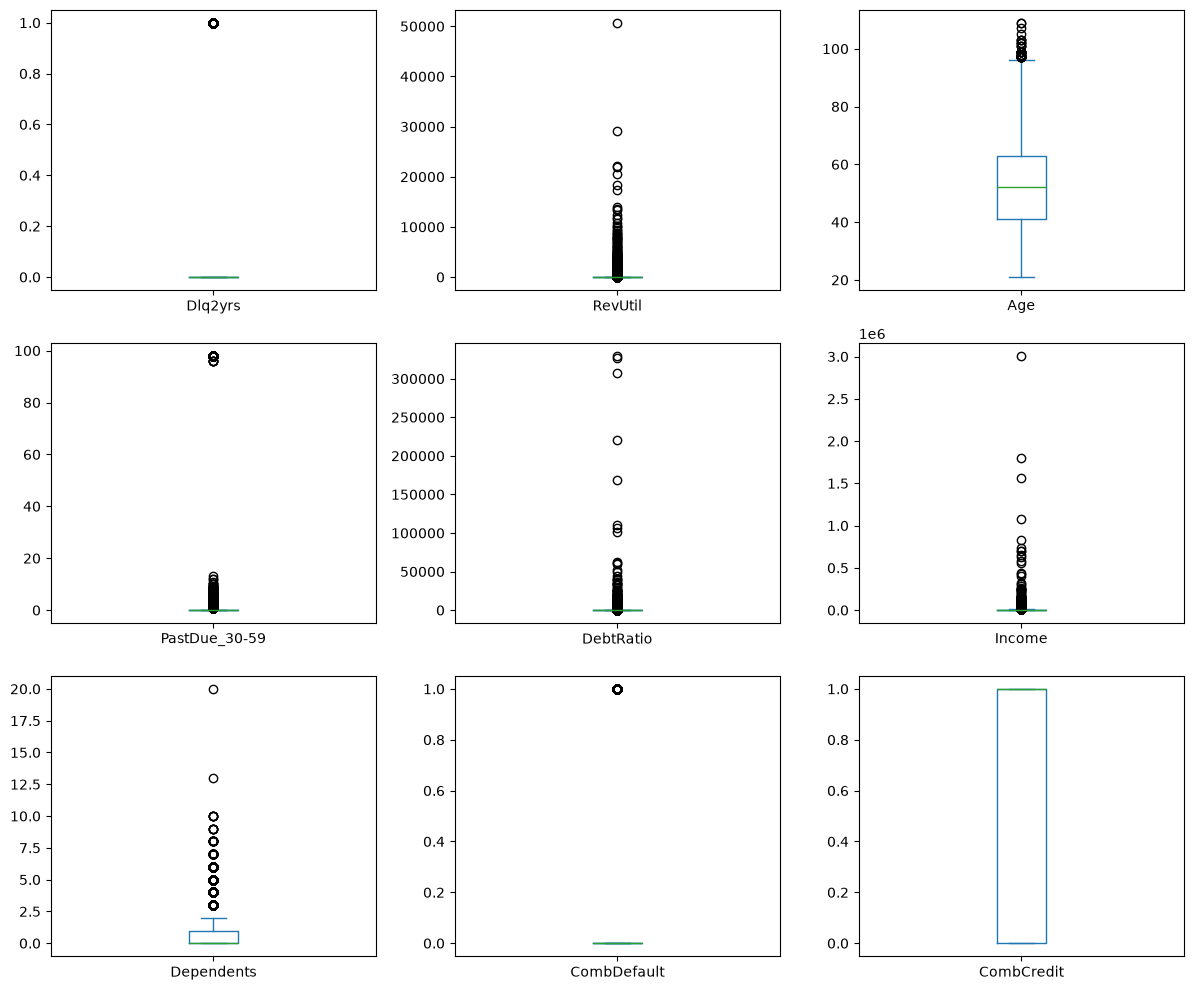

In [7]:
data.plot(figsize=(12, 10), kind='box', subplots=True, layout=(3, 3), sharex=False, sharey=False)
plt.tight_layout()
plt.show();

## Multivariate
### Correlation Matrix Plot (Seaborn)

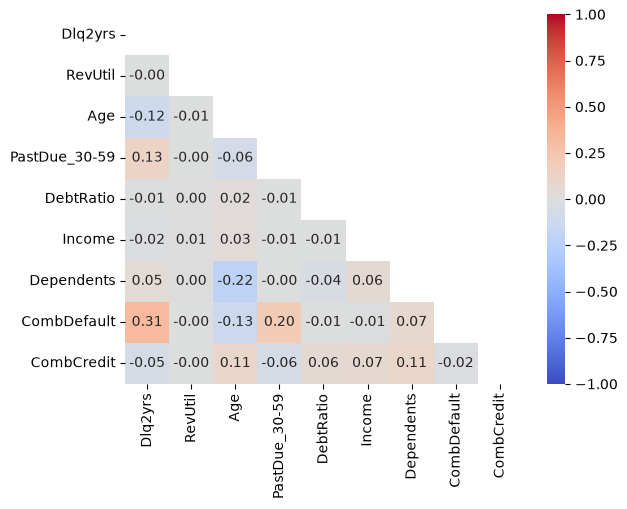

In [8]:
import numpy as np
import seaborn as sns
corr = data.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.show();

### Scatter Plot Matrix

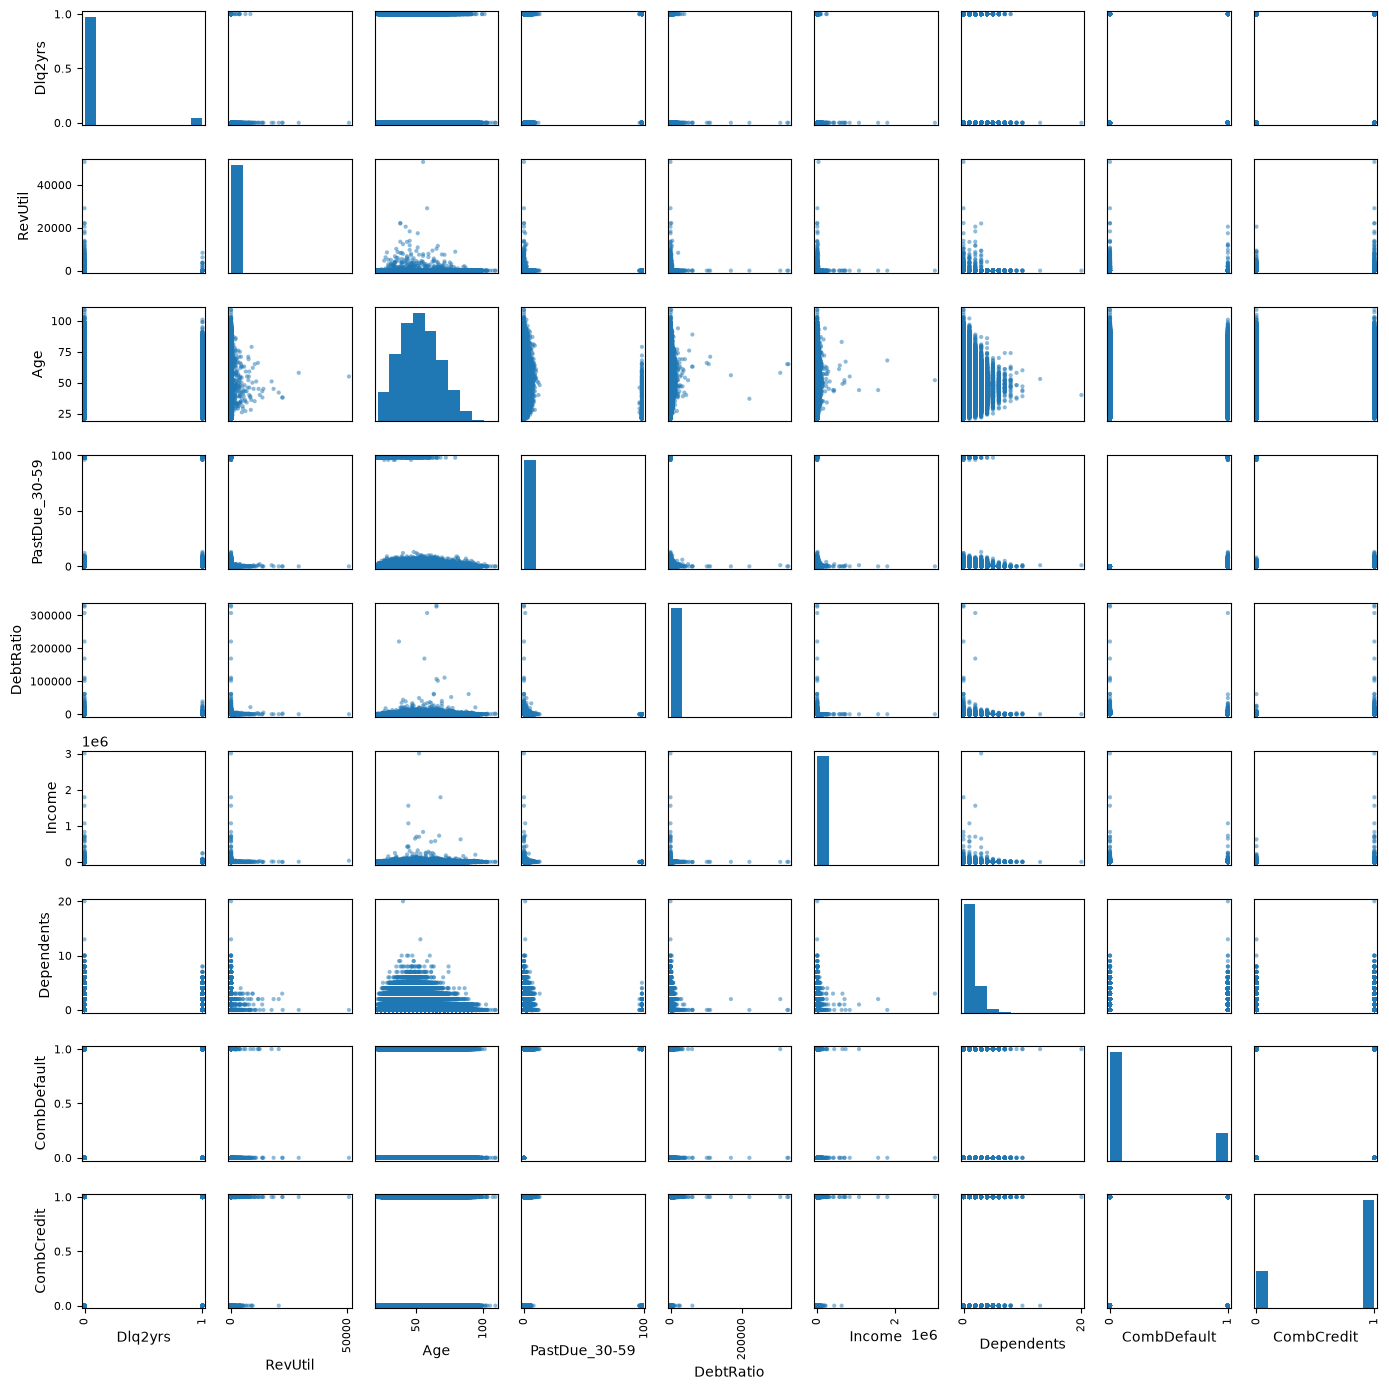

In [9]:
from pandas.plotting import scatter_matrix

scatter_matrix(data, figsize=(14, 14), diagonal='hist')
plt.tight_layout()
plt.show();

# Data Preparation
## Rescale
### MinMaxScaler

In [10]:
from sklearn.preprocessing import MinMaxScaler

ar = data.values
X = ar[:, 1:]
Y = ar[:,0]
mmScaler = MinMaxScaler(feature_range=(0, 1))
mmRescaledX = mmScaler.fit_transform(X)

print(mmRescaledX[:5].round(3))

[[0.    0.273 0.02  0.    0.003 0.1   1.    1.   ]
 [0.    0.216 0.    0.    0.001 0.05  0.    0.   ]
 [0.    0.193 0.01  0.    0.001 0.    1.    0.   ]
 [0.    0.102 0.    0.    0.001 0.    0.    0.   ]
 [0.    0.318 0.01  0.    0.021 0.    1.    1.   ]]


### StandardScaler

In [11]:
from sklearn.preprocessing import StandardScaler

stdScaler = StandardScaler().fit(X)
stdRescaledX = stdScaler.transform(X)
print(stdRescaledX[:5].round(3))

[[-0.021 -0.494  0.377 -0.173  0.19   1.141  1.985  0.589]
 [-0.02  -0.832 -0.1   -0.173 -0.316  0.237 -0.504 -1.698]
 [-0.022 -0.968  0.138 -0.173 -0.282 -0.666  1.985 -1.698]
 [-0.023 -1.509 -0.1   -0.173 -0.262 -0.666 -0.504 -1.698]
 [-0.021 -0.223  0.138 -0.173  4.419 -0.666  1.985  0.589]]


### Normalizer

In [12]:
from sklearn.preprocessing import Normalizer

normScaler = Normalizer().fit(X)
normalizedX = normScaler.transform(X)
print(normalizedX[:5].round(3))

[[0.    0.005 0.    0.    1.    0.    0.    0.   ]
 [0.    0.015 0.    0.    1.    0.    0.    0.   ]
 [0.    0.012 0.    0.    1.    0.    0.    0.   ]
 [0.    0.009 0.    0.    1.    0.    0.    0.   ]
 [0.    0.001 0.    0.    1.    0.    0.    0.   ]]


### Binarizer

In [13]:
from sklearn.preprocessing import Binarizer

binScaler = Binarizer().fit(X)
binarizedX = binScaler.transform(X)
print(binarizedX[:5].round(3))

[[1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 0. 1. 1. 1. 0. 0.]
 [1. 1. 1. 1. 1. 0. 1. 0.]
 [1. 1. 0. 1. 1. 0. 0. 0.]
 [1. 1. 1. 1. 1. 0. 1. 1.]]


# Feature Selection
Target에 관련이 적은 Feature는 모델 성능에 부정적 영향.  
Feature Selection은 Target에 가장 크게 기여하는 Feature를 선별.  
Feature Selection의 이점:
- 과적합 감소: 특정 데이터셋에만 과도하게 학습되는 현상 감소
- 정확도 향상: 예측을 저해하는 데이터 감소로 정확도 향상
- 훈련 시간 단축: 학습 데이터를 줄여 학습 시간 감소
## Select K-Score Best - chi2


In [14]:
from sklearn.feature_selection import SelectKBest, chi2

chi2test = SelectKBest(score_func=chi2, k=4)
fit = chi2test.fit(X,Y)

score = pd.DataFrame({'Feature': data.columns[1:], 'Chi2_Score': fit.scores_})
score.set_index('Feature')

features = fit.transform(X)
print(features[:5])

,Chi2_Score
Feature,
RevUtil,5.020472e+03
Age,8.333822e+03
PastDue_30-59,9.877918e+04
DebtRatio,1.019783e+05
Income,1.223268e+06
Dependents,5.475969e+02
CombDefault,1.182635e+04
CombCredit,1.159044e+02


[[2.00000000e+00 8.02982129e-01 9.12000000e+03 1.00000000e+00]
 [0.00000000e+00 1.21876201e-01 2.60000000e+03 0.00000000e+00]
 [1.00000000e+00 8.51133750e-02 3.04200000e+03 1.00000000e+00]
 [0.00000000e+00 3.60496820e-02 3.30000000e+03 0.00000000e+00]
 [1.00000000e+00 2.49256950e-02 6.35880000e+04 1.00000000e+00]]


## Recursive Feature Elimination

In [15]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver='liblinear')
rfe = RFE(estimator=model, n_features_to_select=3)
fit = rfe.fit(X, Y)
print(f"Num Features: {fit.n_features_}")
print(f"Selected Features: {fit.support_}")
print(f"Feature Ranking: {fit.ranking_}")

Num Features: 3
Selected Features: [False False False False False  True  True  True]
Feature Ranking: [4 2 3 6 5 1 1 1]


## Data Reduction using Principal Component Analysis

In [16]:
from sklearn.decomposition import PCA

pca = PCA(n_components=3)
fit = pca.fit(X)

print(f"Explained Variance: {fit.explained_variance_ratio_}")
print(fit.components_)

Explained Variance: [9.75222480e-01 2.44094841e-02 3.66643504e-04]
[[ 1.27252413e-04  3.86916861e-05 -2.50711293e-06 -8.60826195e-04
   9.99999621e-01  4.98497053e-06 -3.35932450e-07  2.31442164e-06]
 [ 4.97344312e-04  1.76646977e-04 -1.35469032e-05  9.99999490e-01
   8.60756016e-04 -2.39903450e-05 -1.03030148e-06  1.22727457e-05]
 [ 9.99999800e-01 -3.69131482e-04 -2.07375550e-05 -4.97169519e-04
  -1.27666200e-04  4.41665443e-06 -2.57858822e-06 -2.39227362e-06]]


## Feature Importance

In [17]:
from sklearn.ensemble import ExtraTreesClassifier

model = ExtraTreesClassifier()
model.fit(X, Y)
print(model.feature_importances_);

[0.25064962 0.12203963 0.04464092 0.25607988 0.20403769 0.02347099
 0.09186998 0.00721129]


# Resampling
## Split into Train and Test Sets

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

test_size = 0.33 # Train : Test = 0.67 : 0.33
seed = 7
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=test_size, random_state=seed)
model = LogisticRegression(solver='liblinear')
model.fit(X_train, Y_train)
result = model.score(X_test, Y_test)
print(f"Accuracy: {result * 100.0}");

Accuracy: 93.34141414141413


## K-fold Cross-Validation

In [19]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LogisticRegression

num_folds = 10
seed = 7
kfold = KFold(n_splits=num_folds, random_state=seed, shuffle=True)
model = LogisticRegression(solver='liblinear')
results = cross_val_score(model, X, Y, cv=kfold)
print(f"Accuracy: {results.mean() * 100.0} ({results.std() * 100.0})")

Accuracy: 93.30599999999998 (0.19862751292026187)


## Leave-One-Out Cross-Validation

In [20]:
# from sklearn.model_selection import LeaveOneOut, cross_val_score
# from sklearn.linear_model import LogisticRegression

# loocv = LeaveOneOut()
# model = LogisticRegression(solver = 'liblinear')
# results = cross_val_score(model, X, Y, cv=loocv)
# print(f"Accuracy: {results.mean()*100.0} ({results.std()*100.0})")

## Repeated Random Test-Train Splits

In [21]:
from sklearn.model_selection import ShuffleSplit, cross_val_score
from sklearn.linear_model import LogisticRegression

n_splits = 10
test_size = 0.33
seed = 7
kfold = ShuffleSplit(n_splits=n_splits, test_size=test_size,  random_state=seed)
model = LogisticRegression(solver = 'liblinear')
results = cross_val_score(model, X, Y, cv=kfold)
print(f"Accuracy: {results.mean()*100.0} ({results.std ()*100.0})")

Accuracy: 93.23898989898989 (0.08780352053618838)


# Evaluation Matrix
## Classification Metrix
### Classification Accuracy

In [22]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LogisticRegression

kfold = KFold(n_splits=10, random_state=7, shuffle=True)
model = LogisticRegression(solver='liblinear')

scoring = 'accuracy'    # Accuracy

results = cross_val_score(model, X, Y, cv=kfold, scoring=scoring)
print(f"Accuracy: {results.mean() * 100.0} ({results.std() * 100.0})")

Accuracy: 93.30599999999998 (0.19862751292026187)


### Logarithmic Loss (LogLoss)

In [23]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LogisticRegression

kfold = KFold(n_splits=10, random_state=7, shuffle=True)
model = LogisticRegression(solver='liblinear')

scoring = 'neg_log_loss'    # LogLoss

results = cross_val_score(model, X, Y, cv=kfold, scoring=scoring)
print(f"Accuracy: {results.mean() * 100.0} ({results.std() * 100.0})")

Accuracy: -20.860096418491505 (0.5052499751325524)


### Area Under ROC Curve (AUROC)

In [24]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LogisticRegression

kfold = KFold(n_splits=10, random_state=7, shuffle=True)
model = LogisticRegression(solver='liblinear')
scoring = 'roc_auc'    # AUROC
results = cross_val_score(model, X, Y, cv=kfold, scoring=scoring)
print(f"Accuracy: {results.mean() * 100.0} ({results.std() * 100.0})")

Accuracy: 79.06296600624017 (1.135552988143407)


### Confusion Matrix & Classification Report

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report

test_size = 0.33
seed = 7
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=test_size, random_state=seed)

model = LogisticRegression(solver='liblinear')
model.fit(X_train, Y_train)
predicted = model.predict(X_test)
matrix = confusion_matrix(Y_test, predicted)
print(matrix);

report = classification_report(Y_test, predicted)
print(report);


[[46154    63]
 [ 3233    50]]
              precision    recall  f1-score   support

         0.0       0.93      1.00      0.97     46217
         1.0       0.44      0.02      0.03      3283

    accuracy                           0.93     49500
   macro avg       0.69      0.51      0.50     49500
weighted avg       0.90      0.93      0.90     49500



# Shortlisting Algorithm
## Logistic Regression

In [26]:
from sklearn.model_selection import KFold, cross_val_score 
from sklearn.linear_model import LogisticRegression 

num_folds = 10 
kfold = KFold(n_splits=10, random_state=7,shuffle=True) 
model = LogisticRegression(solver='liblinear') 
results = cross_val_score(model, X, Y, cv=kfold) 
print(results.mean() * 100.0)

93.30599999999998


## K-Nearest Neighbors (KNN)

In [27]:
from sklearn.model_selection import KFold, cross_val_score 
from sklearn.neighbors import KNeighborsClassifier

num_folds = 10 
kfold = KFold(n_splits=10, random_state=7,shuffle=True) 
model = KNeighborsClassifier()
results = cross_val_score(model, X, Y, cv=kfold) 
print(results.mean() * 100.0)

93.07866666666665


## Support Vector Machines (SVM)

In [28]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.svm import SVC
X_sample, _, Y_sample, _ = train_test_split(X, Y, train_size=10000, stratify=Y, random_state=seed)
num_folds = 10 
kfold = KFold(n_splits=10, random_state=7,shuffle=True) 
model = SVC()
results = cross_val_score(model, X_sample, Y_sample, cv=kfold) 
print(results.mean() * 100.0)

93.32000000000001


## Classification and Regression Trees (CART or Decision Trees)

              precision    recall  f1-score   support

         0.0       0.93      1.00      0.97     13984
         1.0       0.68      0.02      0.04      1016

    accuracy                           0.93     15000
   macro avg       0.81      0.51      0.50     15000
weighted avg       0.92      0.93      0.90     15000



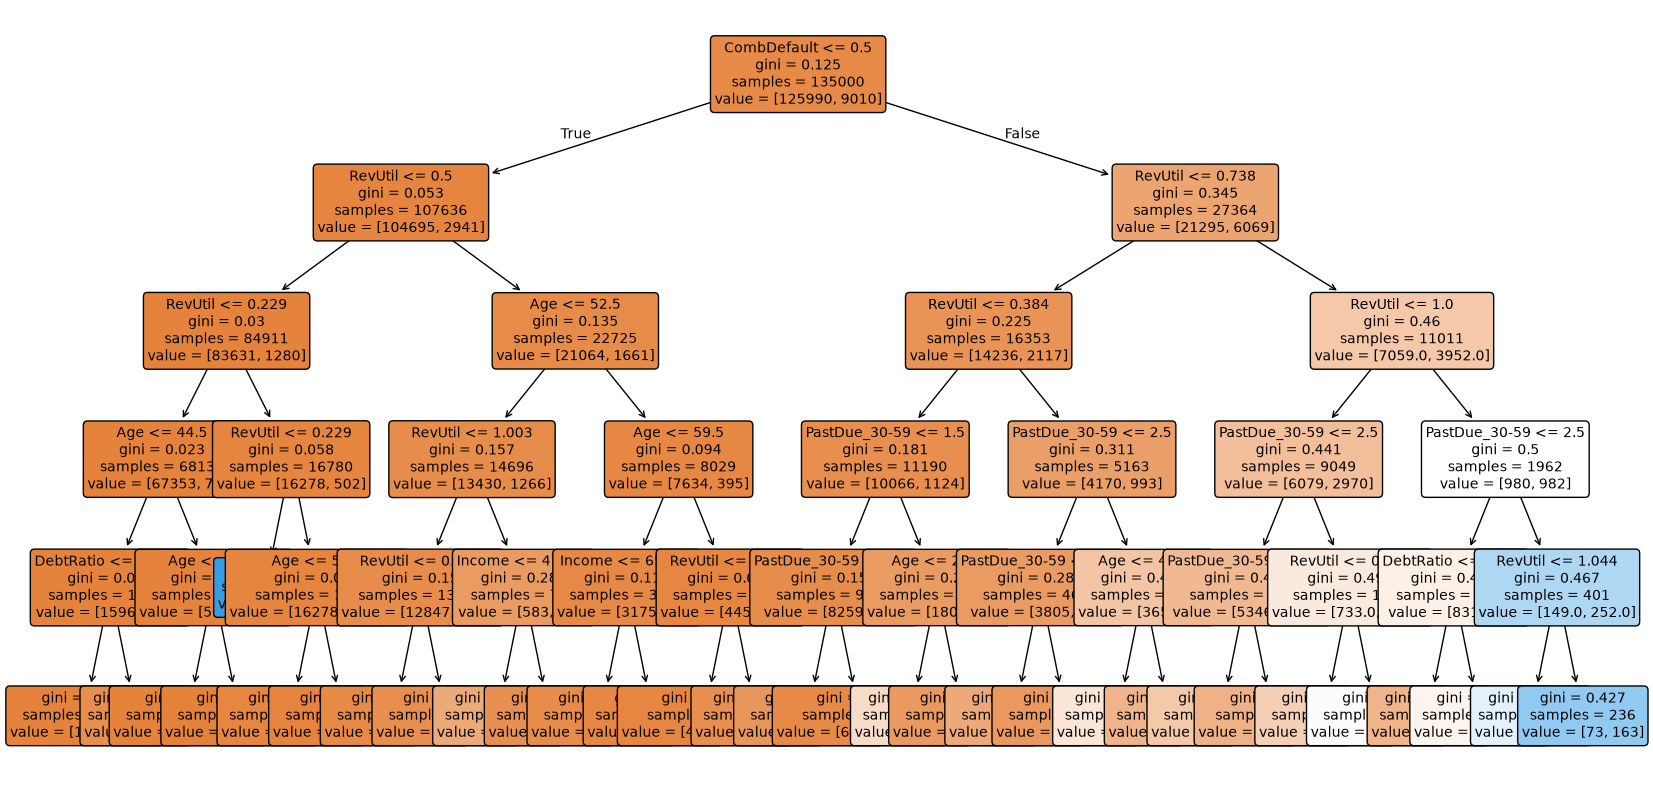

In [29]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import classification_report
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_graphviz

test_size = 0.1
seed = 7

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=test_size, random_state=seed)

model = DecisionTreeClassifier(max_depth=5, random_state=seed)
model.fit(X_train, Y_train)
predicted = model.predict(X_test)
report = classification_report(Y_test, predicted)
print(report);

plt.figure(figsize=(20, 10))
plot_tree(
    model,
    feature_names=data.columns[1:],
    rounded=True,
    filled=True,
    fontsize=10
)
plt.show();

# Comparing ML Algorithms
- Logistic Regression (LR)
- Linear Discriminant Analysis (LDA)
- K-Nearest Neighbors (KNN)
- Classification and Regression Tree (CART)
- Naive Bayes (NB)
- Support Vector Machines (SVM)

LR: 93.32 (0.04)
LDA: 93.26 (0.07)
KNN: 92.64 (0.09)
CART: 89.40 (0.16)
NB: 93.11 (0.11)
SVM: 93.33 (0.05)


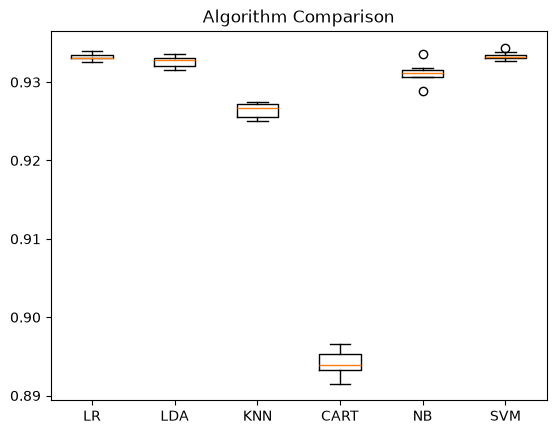

In [30]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC

models = []
models.append(('LR', make_pipeline(StandardScaler(), LogisticRegression(solver='liblinear'))))
models.append(('LDA', LinearDiscriminantAnalysis()))
models.append(('KNN', make_pipeline(StandardScaler(),KNeighborsClassifier())))
models.append(('CART', DecisionTreeClassifier(random_state=7)))
models.append(('NB', GaussianNB()))
models.append(('SVM', make_pipeline(StandardScaler(), LinearSVC(random_state=7))))

results, names = [], []
scoring = 'accuracy'
kfold = StratifiedKFold(n_splits=10, random_state=7, shuffle=True)

for name, model in models:
    
    cv_results = cross_val_score(model, X, Y, cv=kfold, scoring=scoring, n_jobs=-1)
    results.append(cv_results)
    names.append(name)
    print(f"{name}: {cv_results.mean() * 100:.2f} ({cv_results.std() * 100:.2f})")

plt.boxplot(results, tick_labels=names)
plt.title('Algorithm Comparison')
plt.show();

# Pipelining
전처리 및 모델 적용에 대해 교차 검증의 각 폴드에서만 적용되도록 제한하여 데이터의 누수를 막는 역할

In [31]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Standardize -> LDA 의 파이프라인 생성
estimators = []
estimators.append(('standardize', StandardScaler()))
estimators.append(('lda', LinearDiscriminantAnalysis()))
model = Pipeline(estimators)

# 10-fold 검정
kfold = KFold(n_splits=10, random_state=7, shuffle=True)
results = cross_val_score(model, X, Y, cv=kfold)
print(f"{results.mean() * 100:.2f}%")

93.27%


## Feature Extraction with Pipeline
여러 특성 선택 및 추출 및 결합 과정이 교차 검증의 각 폴드 내로 국한됨

In [33]:
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest

# 특성 결합
features = []
features.append(('pca', PCA(n_components=3)))
features.append(('select_best', SelectKBest(k=6)))
feature_union = FeatureUnion(features)

# 파이프라인 생성
estimators = []
estimators.append(('standardize', StandardScaler()))
estimators.append(('feature_union', feature_union))
estimators.append(('logistic', LogisticRegression()))
model = Pipeline(estimators)

# 파이프라인 평가
kfold = KFold(n_splits=10, random_state=7, shuffle=True)
results = cross_val_score(model, X, Y, cv=kfold)
print(f"{results.mean() * 100:.2f}")

93.32


# Ensembles
## Bagging Algorithms
### Decision Tree Bagging

In [39]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

cart = DecisionTreeClassifier(max_depth=10)
num_trees = 100

model = BaggingClassifier(estimator=cart, n_estimators=num_trees, random_state=seed, n_jobs=-1)
results = cross_val_score(model, X, Y, cv=kfold)
print(f"{results.mean():.2f}")

0.93


### Random Forest Bagging

In [41]:
from sklearn.ensemble import RandomForestClassifier

num_trees = 100
max_features = 3
kfold = KFold(n_splits=10, random_state=7, shuffle=True)

model = RandomForestClassifier(n_estimators=num_trees, max_features=max_features, max_depth=10, random_state=7, n_jobs=-1)
results = cross_val_score(model, X, Y, cv=kfold)
print(results.mean())

0.9344866666666667


## Boosting Algorithms
### Adaboost

In [38]:
from sklearn.ensemble import AdaBoostClassifier

num_trees = 30
seed = 7
model = AdaBoostClassifier(n_estimators=num_trees, random_state=seed)
results = cross_val_score(model, X, Y, cv=kfold)
print(results.mean())

0.9341266666666668


## Voting Ensemble

In [47]:
from pandas import read_csv 
from sklearn.model_selection import KFold 
from sklearn.model_selection import cross_val_score 
from sklearn.linear_model import LogisticRegression 
from sklearn.tree import DecisionTreeClassifier 
from sklearn.svm import LinearSVC 
from sklearn.ensemble import VotingClassifier 

kfold = KFold(n_splits=10, random_state=7, shuffle=True)

# create the sub models 
estimators = []
model1 = LogisticRegression() 
estimators.append(('logistic', model1)) 
model2 = DecisionTreeClassifier() 
estimators.append(('cart', model2)) 
model3 = LinearSVC(random_state=7)
estimators.append(('svm', model3))

# create the ensemble model 
ensemble = make_pipeline(StandardScaler(), VotingClassifier(estimators) )
results = cross_val_score(ensemble, X, Y, cv=kfold) 
print(results.mean())

0.9333200000000001


# Tuning
## Grid Search

In [49]:
from sklearn.linear_model import Ridge 
from sklearn.model_selection import GridSearchCV 

alphas = np.array([1,0.1,0.01,0.001,0.0001,0]) 
param_grid = dict(alpha=alphas) 
model = Ridge() 
grid = GridSearchCV(estimator=model, param_grid=param_grid) 
grid.fit(X, Y) 
print(grid.best_score_);
print(grid.best_estimator_.alpha);

0.10974307194783994
1.0


## Random Search

In [60]:
from scipy.stats import uniform
from sklearn.model_selection import RandomizedSearchCV

param_grid = {'alpha': uniform()}
model = Ridge()
rsearch = RandomizedSearchCV(estimator=model, param_distributions=param_grid, n_iter=100, random_state=7, n_jobs=-1)
rsearch.fit(X, Y)

print(rsearch.best_score_);
print(rsearch.best_estimator_.alpha);


0.10974307176638301
0.9779895119966027


# Saving and Loading Models
## Pickle

In [59]:
from pickle import dump, load

print(rsearch.score(X_test, Y_test))

# 모델 저장
filename = 'finalized_model.sav'
dump(rsearch, open(filename, 'wb'))

# 모델 로드
loaded_model = load(open(filename, 'rb'))
result = loaded_model.score(X_test, Y_test)
result

0.12100761914331581


0.12100761914331581

## Joblib

In [62]:
from joblib import dump, load

filename = 'finalized_model2.sav'
dump(rsearch, filename)

loaded_model = load(filename)
result = loaded_model.score(X_test, Y_test)
result

['finalized_model2.sav']

0.12100761914331581

# Keras API / Deep Learning with MLP
## Load Data

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
import numpy as np
import pandas as pd
from keras.models import Sequential
from keras.layers import Input, Dense

np.random.seed(7)

dataset = pd.read_csv("givemesomecredit.csv").values

X = dataset[:,1:]
Y = dataset[:,0]

## Define Model
### Create Sequential Model

In [2]:
model = Sequential()
model.add(Input(shape=(8,)))
model.add(Dense(12, activation='relu'))
model.add(Dense(8, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

## Compile Model

In [3]:
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

## Evaluate Model
### Evaluate Model

In [4]:
scores = model.evaluate(X, Y)
print(f"{model.metrics_names[1]}: {scores[1] * 100}")

4688/4688 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step - accuracy: 0.0986 - loss: 1226.5570
compile_metrics: 9.863333404064178


### Save Weight

In [5]:
import os
try:
    os.remove("weights.out")
    print("old file deleted")
except:
    print("no file to delete")

weights = model.get_weights()
with open("weights.out", "ab") as f:
    for item in weights:
        np.savetxt(f, item, delimiter=',')

no file to delete


## Data Splitting
### Automatic Verification Dataset

In [13]:
model.fit(X, Y, validation_split=0.33, epochs=150, batch_size=512)

Epoch 1/150
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9334 - loss: 0.1949 - val_accuracy: 0.9327 - val_loss: 0.1985
Epoch 2/150
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9334 - loss: 0.1963 - val_accuracy: 0.9327 - val_loss: 0.1998
Epoch 3/150
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9334 - loss: 0.1939 - val_accuracy: 0.9327 - val_loss: 0.2015
Epoch 4/150
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9334 - loss: 0.1948 - val_accuracy: 0.9327 - val_loss: 0.2040
Epoch 5/150
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9334 - loss: 0.1958 - val_accuracy: 0.9327 - val_loss: 0.1985
Epoch 6/150
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9334 - loss: 0.1949 - val_accuracy: 0.9327 - val_loss: 0.2112
Epoch 7/150
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9334 - loss: 0.1956 - val_accuracy: 0.9327 - val_loss: 0.2052
Epoch 8/150
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9334 - loss: 0.1947 - val_accu

### Manual Verification Dataset

In [14]:
from sklearn.model_selection import train_test_split 

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.33, 
random_state=seed)
model.fit(X_train, Y_train, validation_data=(X_test, Y_test), epochs=100, batch_size=1024)

Epoch 1/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.9329 - loss: 0.1944 - val_accuracy: 0.9337 - val_loss: 0.1992
Epoch 2/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9329 - loss: 0.1934 - val_accuracy: 0.9337 - val_loss: 0.2192
Epoch 3/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9329 - loss: 0.1953 - val_accuracy: 0.9337 - val_loss: 0.2035
Epoch 4/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9329 - loss: 0.1938 - val_accuracy: 0.9337 - val_loss: 0.2026
Epoch 5/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9329 - loss: 0.1928 - val_accuracy: 0.9337 - val_loss: 0.2055
Epoch 6/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9329 - loss: 0.1931 - val_accuracy: 0.9337 - val_loss: 0.2014
Epoch 7/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9329 - loss: 0.1938 - val_accuracy: 0.9337 - val_loss: 0.2111
Epoch 8/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9329 - loss: 0.1930 - val_accuracy: 0.9337 - 

## Manual K-Fold Cross-Validation

In [19]:
from sklearn.model_selection import StratifiedKFold

seed = 7
np.random.seed(seed)

kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
cvscores = []

for train, test in kfold.split(X, Y):
    # 매 폴드마다 모델을 새롭게 생성
    model = Sequential()
    model.add(Input(shape=(8,)))
    model.add(Dense(12, activation='relu'))
    model.add(Dense(8, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
    
    # 훈련 (verbose=0으로 세부 출력 끄기)
    model.fit(X[train], Y[train], epochs=50, batch_size=1024, verbose=0)
    
    # 평가
    scores = model.evaluate(X[test], Y[test], verbose=0)
    print("%s: %.2f%%" % (model.metrics_names[1], scores[1]*100))
    cvscores.append(scores[1] * 100)

print("%.2f%% (+/- %.2f%%)" % (np.mean(cvscores), np.std(cvscores)))

KeyboardInterrupt: 

# Use Keras with Scikit-Learn
## Evaluate Models with Cross-Validation

In [ ]:
from scikeras.wrappers import KerasClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 모델을 구축하고 반환하는 함수 정의
def create_model():
    model = Sequential()
    model.add(Input(shape=(8,)))
    model.add(Dense(12, activation='relu'))
    model.add(Dense(8, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

model = KerasClassifier(model=create_model, epochs=150, batch_size=1024, verbose=0)

kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)
results = cross_val_score(model, X, Y, cv=kfold)
print(results.mean())

RuntimeError: Physical devices cannot be modified after being initialized